# Personalized Driving Behaviour Guidance Module

### Dataset 1 (Munich / TUM real-driving-cycle EV telemetry)

This notebook builds the complete driving-behaviour pipeline for the project: preprocessing the Munich trip telemetry, exploring driving and battery patterns, engineering behavioural and battery features, training a model that links driving behaviour to battery stress, explaining it with SHAP, and turning the explanation into personalized per-trip driving recommendations.

## Dataset

The `dataset soh/` folder contains real-world telemetry from a single BMW i3-class EV (TUM FTM's *"Battery and Heating Data in Real Driving Cycles"* dataset), logged at 10 Hz across **70 trips** (`TripA01`–`TripA32`, `TripB01`–`TripB38`) between **2019-06-25 and 2020-02-07**. Each trip CSV records velocity, longitudinal acceleration, throttle, motor torque, battery voltage/current/temperature, SoC, ambient temperature, and HVAC signals. `Overview.xlsx` supplies one metadata row per trip: start timestamp, route/area, weather, battery/ambient temperature at start and end, SoC at start and end, distance, and duration.

## A note on the modeling target

**This dataset has no measured battery degradation, SOH, or capacity-fade ground truth** — it is single-vehicle telemetry collected over 8 months, not a multi-year aging study. So "estimating the impact of driving behaviour on battery degradation" cannot be a regression against a measured label. Instead, Section 4 constructs a **Battery Stress Index**: a transparent, literature-informed proxy built from the four factors best-established in battery-aging research — operating temperature, C-rate (current relative to pack capacity), depth-of-discharge, and time spent at extreme SoC — each of which *is* measured in this dataset. A model is then trained to predict this index **from driving-behaviour features only** (speed, acceleration, braking, idle time, aggressiveness — never from the battery-internal signals used to build the label itself, which would be trivial leakage). SHAP then explains which driving behaviours push predicted stress up or down, and that explanation drives the personalized recommendations in Section 6.

battery_stress_index = 100 × (
    0.35 × minmax(battery_temp_max_c)        # thermal stress
  + 0.30 × minmax(c_rate_max)                # C-rate stress
  + 0.20 × minmax(max(soc_delta, 0))         # depth-of-discharge
  + 0.15 × minmax(soc_extreme_exposure)      # SoC-extreme exposure
)

## Assumptions used throughout (stated once, referenced later)

- **Nominal pack capacity ≈ 60 Ah** — used for C-rate and for coulomb-counting reconstruction of dropped SoC readings. Validated in Section 1 against the vehicle's own measured SoC delta.
- **Sliding windows of 60 s, 50% overlap (30 s step)** are the unit of analysis for feature engineering and modeling — long enough to characterize a driving segment, short enough to yield a workable sample size (~3,200 windows) from 70 trips.
- **Battery current sign convention**: negative = discharge, positive = charge/regen (confirmed empirically in Section 1).


In [1]:
import os
import sys
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

warnings.filterwarnings("ignore")

# Windows' default console codepage (cp1252) can't encode characters used below
# (e.g. "•", "²"); force UTF-8 stdout so printed output isn't silently mangled.
if sys.stdout.encoding is not None and sys.stdout.encoding.lower() != "utf-8":
    sys.stdout.reconfigure(encoding="utf-8")

# ---- paths -------------------------------------------------------------
DATA_DIR = os.path.join("..", "dataset soh")
OUT_FIG_DIR = os.path.join("outputs", "figures")
OUT_DATA_DIR = os.path.join("outputs", "data")
OUT_MODEL_DIR = os.path.join("outputs", "model")
for d in (OUT_FIG_DIR, OUT_DATA_DIR, OUT_MODEL_DIR):
    os.makedirs(d, exist_ok=True)

# ---- domain assumptions --------------------------------
NOMINAL_CAPACITY_AH = 60.0   # BMW i3 (60 Ah) pack, used for C-rate & coulomb counting
WINDOW_S = 60                # sliding-window length, seconds
STEP_S = 30                  # sliding-window step (50% overlap), seconds
FS_HZ = 10                   # sample rate of the raw telemetry (0.1 s per sample)
HARD_ACCEL_THRESH = 2.0      # m/s^2, threshold for a "hard acceleration" event
HARD_BRAKE_THRESH = -2.0     # m/s^2, threshold for a "hard braking" event
IDLE_SPEED_KMH = 1.0         # below this speed the vehicle counts as idle/stopped
BRAKING_ACCEL_THRESH = -0.5  # m/s^2, threshold above which we call it "braking" at all
MIN_WINDOW_DISTANCE_KM = 0.1 # drop near-stationary/charging windows below this

# ---- plotting style (fixed categorical palette, validated for CVD-safety) ----
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#184f95"]
sns.set_theme(style="whitegrid", rc={
    "axes.facecolor": "#fcfcfb",
    "figure.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "grid.color": "#e1e0d9",
    "text.color": "#0b0b0b",
    "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "font.family": "sans-serif",
})
mpl.rcParams["axes.prop_cycle"] = mpl.cycler(color=PALETTE)
pd.set_option("display.max_columns", 60)

RANDOM_STATE = 42

## Section 1 — Data Loading & Preprocessing

Steps performed here, specific to this dataset's quirks:

1. **Robust column resolution.** The 70 CSVs are not schema-identical — some trips log 22 columns, others up to 48 (extra HVAC vent sensors), and a couple of headers have typos/stray characters (e.g. `TripB38`'s velocity column). We resolve the columns we need by keyword matching rather than exact-name matching.
2. **Timestamp construction.** Each row only has a trip-relative `Time [s]`; we combine it with the trip's start timestamp from `Overview.xlsx` to get an absolute datetime.
3. **Missing-value handling.** The SoC signal drops out (goes `NaN`) for the remainder of the trip in several files — up to 60% of one trip. We reconstruct it via coulomb counting (integrating battery current from the last valid SoC reading) rather than naive interpolation, since a straight-line interpolation to an unknown endpoint would be meaningless over a 10+ minute gap.
4. **Noise handling.** The raw longitudinal-acceleration signal is lightly denoised with a rolling median before it's used to detect hard-acceleration/braking events, so sensor jitter doesn't get miscounted as events.

In [2]:
def load_overview():
    """Load Overview.xlsx into a tidy per-trip metadata table."""
    df = pd.read_excel(os.path.join(DATA_DIR, "Overview.xlsx"), sheet_name="Overview")
    df = df.dropna(subset=["Trip"]).copy()
    df = df.rename(columns={
        "Trip": "trip_id",
        "Date": "start_datetime_raw",
        "Route/Area": "route",
        "Weather": "weather",
        "Battery Temperature (Start) [\xb0C]": "batt_temp_start_c",
        "Battery Temperature (End)": "batt_temp_end_c",
        "Battery State of Charge (Start)": "soc_start_frac",
        "Battery State of Charge (End)": "soc_end_frac",
        "Ambient Temperature (Start) [\xb0C]": "ambient_temp_start_c",
        "Target Cabin Temperature": "target_cabin_temp_c",
        "Distance [km]": "distance_km",
        "Duration [min]": "duration_min",
        "Fan": "fan",
        "Note": "note",
    })
    # Two date formats are used in the source file ("2019-06-25_13-21-14" and
    # "2019_12_08_09-38-26"); normalizing all separators to "-" makes them parse uniformly.
    normalized = df["start_datetime_raw"].str.replace("_", "-", regex=False)
    df["start_datetime"] = pd.to_datetime(normalized, format="%Y-%m-%d-%H-%M-%S")
    keep = ["trip_id", "start_datetime", "route", "weather", "batt_temp_start_c", "batt_temp_end_c",
            "soc_start_frac", "soc_end_frac", "ambient_temp_start_c", "target_cabin_temp_c",
            "distance_km", "duration_min", "fan", "note"]
    return df[keep].reset_index(drop=True)


def resolve_columns(df):
    """Map this trip's (schema-variable) raw headers onto the canonical fields we need."""
    def find(keywords, exclude=()):
        for orig in df.columns:
            name = orig.strip().lower()
            if all(k.lower() in name for k in keywords) and not any(e.lower() in name for e in exclude):
                return orig
        return None

    mapping = {
        "time_s": find(["time", "[s]"]),
        "velocity_kmh": find(["velocity"]),
        "elevation_m": find(["elevation"]),
        "throttle_pct": find(["throttle"]),
        "motor_torque_nm": find(["motor torque"]),
        "accel_ms2": find(["longitudinal acceleration"]),
        "regen_signal": find(["regenerative braking"]),
        "batt_voltage_v": find(["battery voltage"]),
        "batt_current_a": find(["battery current"]),
        "batt_temp_c": find(["battery temperature"], exclude=("max.",)),
        "soc_pct": find(["soc"], exclude=("displayed", "min.", "max.")),
        "ambient_temp_c": find(["ambient temperature"], exclude=("sensor",)),
    }
    missing = [k for k, v in mapping.items() if v is None]
    if missing:
        raise ValueError(f"Missing required columns {missing} in columns={list(df.columns)}")
    return mapping


overview = load_overview()
print(f"Overview metadata: {overview.shape[0]} trips, {overview.shape[1]} fields")
overview.head(3)

Overview metadata: 70 trips, 14 fields


,trip_id,start_datetime,route,weather,batt_temp_start_c,batt_temp_end_c,soc_start_frac,soc_end_frac,ambient_temp_start_c,target_cabin_temp_c,distance_km,duration_min,fan,note
0,TripA01,2019-06-25 13:21:14,Munich East,sunny,21.0,22.0,0.863,0.803,25.5,23.0,7.427690,16.82,"Automatic, Level 1",NaN
1,TripA02,2019-06-25 14:05:31,Munich East,sunny,23.0,26.0,0.803,0.673,32.0,23.0,23.509709,23.55,"Automatic, Level 1",Target Cabin Temperature changed
2,TripA03,2019-06-28 10:02:15,Munich East,sunny,24.0,25.0,0.835,0.751,21.5,27.0,12.820846,11.18,"Automatic, Level 1",Target Cabin Temperature changed


In [3]:
def reconstruct_soc(time_s, soc_pct, batt_current_a):
    """Fill missing SoC readings.

    Short/leading gaps are back/interpolated. Long trailing gaps (the CAN signal
    group drops out for the rest of the trip in several files) are reconstructed via
    coulomb counting: integrate the (still-valid) battery current from the last known
    SoC reading, using the assumed nominal pack capacity. Result is clipped to
    [0, 100] since SoC cannot physically leave that range (this matters for the one
    trip in this dataset with a fast-charging stop, where the reconstruction would
    otherwise overshoot 100% before the real BMS's own charge-limiting kicks in).
    """
    soc = soc_pct.copy()
    n = len(soc)
    stats = {"leading_backfilled": 0, "coulomb_reconstructed": 0, "interpolated": 0}
    if soc.isna().sum() == 0:
        return soc, stats

    if pd.isna(soc.iloc[0]):
        first_valid = soc.first_valid_index()
        if first_valid is not None:
            stats["leading_backfilled"] = first_valid
            soc.iloc[:first_valid] = soc.iloc[first_valid]

    last_valid = soc.last_valid_index()
    if last_valid is not None and last_valid < n - 1:
        t = time_s.values
        I = batt_current_a.values
        dt = np.diff(t, prepend=t[0])
        tail_idx = np.arange(last_valid + 1, n)
        cum_ah = np.cumsum(I[tail_idx] * dt[tail_idx]) / 3600.0
        soc_reconstructed = soc.iloc[last_valid] + (cum_ah / NOMINAL_CAPACITY_AH) * 100.0
        soc.iloc[tail_idx] = np.clip(soc_reconstructed, 0.0, 100.0)
        stats["coulomb_reconstructed"] = len(tail_idx)

    remaining = soc.isna().sum()
    if remaining > 0:
        stats["interpolated"] = int(remaining)
        soc = soc.interpolate(method="linear", limit_direction="both")
    return soc, stats


def load_trip(path):
    """Load one trip CSV into a clean, canonically-named dataframe."""
    raw = pd.read_csv(path, sep=";", encoding="latin1")
    cmap = resolve_columns(raw)
    df = raw[[cmap[k] for k in cmap]].copy()
    df.columns = list(cmap.keys())
    for c in df.columns:
        if c != "regen_signal":
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df["accel_smooth"] = df["accel_ms2"].rolling(5, center=True, min_periods=1).median()
    soc_fixed, stats = reconstruct_soc(df["time_s"], df["soc_pct"], df["batt_current_a"])
    df["soc_pct"] = soc_fixed
    return df, stats


# --- validate the current-sign convention on one trip (used in the docstring above) ---
_sample, _ = load_trip(os.path.join(DATA_DIR, "TripA01.csv"))
_soc_delta = _sample["soc_pct"].iloc[-1] - _sample["soc_pct"].iloc[0]
_dt = np.diff(_sample["time_s"].values, prepend=_sample["time_s"].values[0])
_ah = np.sum(_sample["batt_current_a"].values * _dt) / 3600.0
print(f"TripA01: measured SoC change = {_soc_delta:.1f} pct pts; integrated current = {_ah:.2f} Ah "
      f"-> implied capacity = {_ah / (_soc_delta/100):.1f} Ah (assumed {NOMINAL_CAPACITY_AH} Ah)")
print("Negative current coincides with falling SoC -> confirms convention: negative = discharge.")

TripA01: measured SoC change = -5.4 pct pts; integrated current = -3.35 Ah -> implied capacity = 62.0 Ah (assumed 60.0 Ah)
Negative current coincides with falling SoC -> confirms convention: negative = discharge.


In [4]:
trip_files = sorted(glob.glob(os.path.join(DATA_DIR, "Trip*.csv")))
meta_by_trip = overview.set_index("trip_id").to_dict("index")

trips = {}          # trip_id -> cleaned dataframe (with absolute datetime)
load_report = []     # per-trip preprocessing diagnostics

for f in trip_files:
    trip_id = os.path.splitext(os.path.basename(f))[0]
    df, stats = load_trip(f)
    meta = meta_by_trip.get(trip_id)
    if meta is not None:
        df["datetime"] = meta["start_datetime"] + pd.to_timedelta(df["time_s"], unit="s")
    trips[trip_id] = df
    load_report.append({
        "trip_id": trip_id, "n_samples": len(df), "duration_s": df["time_s"].iloc[-1],
        "residual_nans": int(df.isna().sum().sum()), **stats,
    })

load_report = pd.DataFrame(load_report)
print(f"Loaded {len(trips)} trips, {load_report['n_samples'].sum():,} total samples "
      f"({load_report['n_samples'].sum()/FS_HZ/3600:.1f} vehicle-hours)")
print(f"Rows with SoC recovered by coulomb-counting: {load_report['coulomb_reconstructed'].sum():,}")
print(f"Rows with residual NaNs after cleaning: {load_report['residual_nans'].sum()}")
load_report[load_report["coulomb_reconstructed"] > 0].sort_values("coulomb_reconstructed", ascending=False)

Loaded 70 trips, 1,094,793 total samples (30.4 vehicle-hours)
Rows with SoC recovered by coulomb-counting: 30,792
Rows with residual NaNs after cleaning: 0


,trip_id,n_samples,duration_s,residual_nans,leading_backfilled,coulomb_reconstructed,interpolated
40,TripB09,56102,5610.1,0,0,20541,0
65,TripB34,7338,733.7,0,0,4407,0
38,TripB07,22899,2289.8,0,0,4175,0
59,TripB28,13665,1366.4,0,0,1625,0
44,TripB13,3545,354.4,0,0,13,0
49,TripB18,11095,1109.4,0,0,2,0
41,TripB10,20233,2023.2,0,0,2,0
51,TripB20,14029,1402.8,0,0,2,0
55,TripB24,9780,977.9,0,0,2,0
67,TripB36,28523,2852.2,0,0,2,0


## Section 2 — Exploratory Data Analysis

First the trip-level picture (from `Overview.xlsx`): what routes, weather, and seasons does this vehicle's usage span? Then within-trip telemetry: what does a driving trip actually look like second-by-second, and how does SoC/battery temperature relate to ambient temperature and driving intensity?

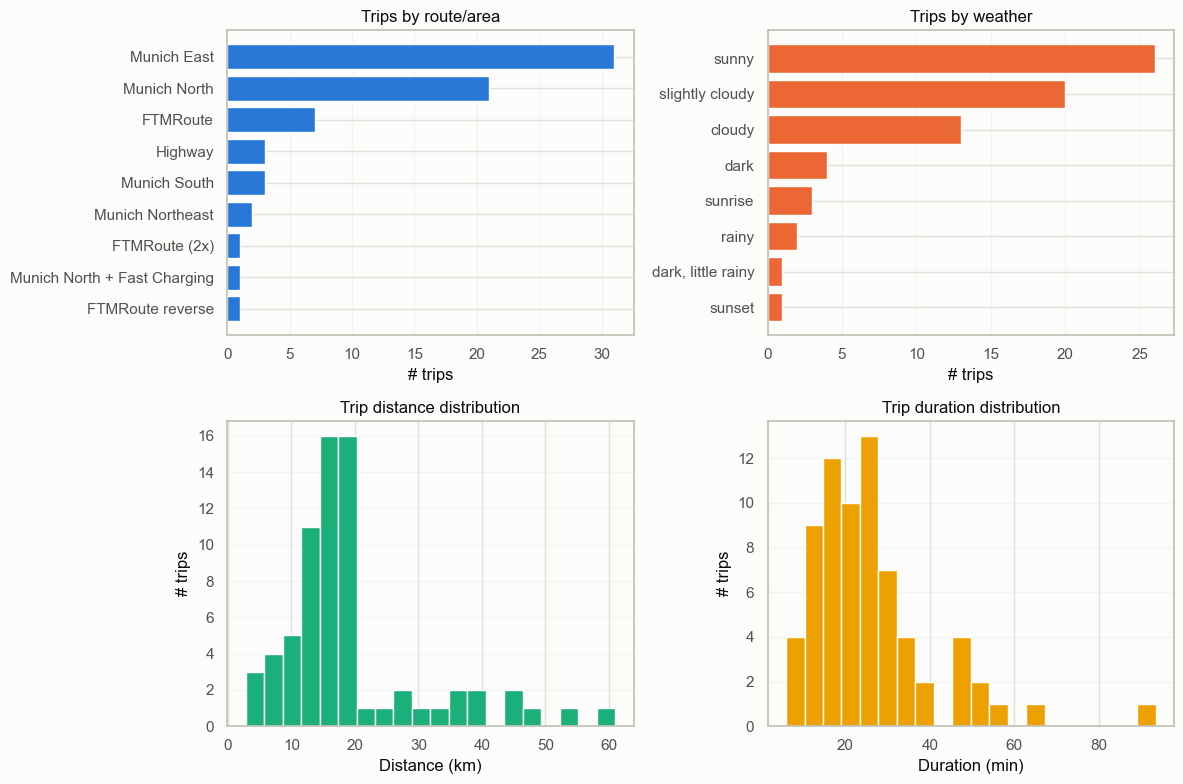

Data spans 2019-06-25 to 2020-02-07 — ambient temperature at trip start ranges -3.0 to 33.5 C (summer through winter conditions).


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

route_counts = overview["route"].value_counts()
axes[0, 0].barh(route_counts.index[::-1], route_counts.values[::-1], color=PALETTE[0])
axes[0, 0].set_title("Trips by route/area")
axes[0, 0].set_xlabel("# trips")

weather_counts = overview["weather"].value_counts()
axes[0, 1].barh(weather_counts.index[::-1], weather_counts.values[::-1], color=PALETTE[1])
axes[0, 1].set_title("Trips by weather")
axes[0, 1].set_xlabel("# trips")

axes[1, 0].hist(overview["distance_km"], bins=20, color=PALETTE[2])
axes[1, 0].set_title("Trip distance distribution")
axes[1, 0].set_xlabel("Distance (km)")
axes[1, 0].set_ylabel("# trips")

axes[1, 1].hist(overview["duration_min"], bins=20, color=PALETTE[3])
axes[1, 1].set_title("Trip duration distribution")
axes[1, 1].set_xlabel("Duration (min)")
axes[1, 1].set_ylabel("# trips")

for ax in axes[0]:
    ax.grid(axis="x", alpha=0.3)
for ax in axes[1]:
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "01_trip_overview.png"), dpi=130)
plt.show()

print(f"Data spans {overview['start_datetime'].min().date()} to {overview['start_datetime'].max().date()}"
      f" — ambient temperature at trip start ranges {overview['ambient_temp_start_c'].min():.1f} to "
      f"{overview['ambient_temp_start_c'].max():.1f} C (summer through winter conditions).")

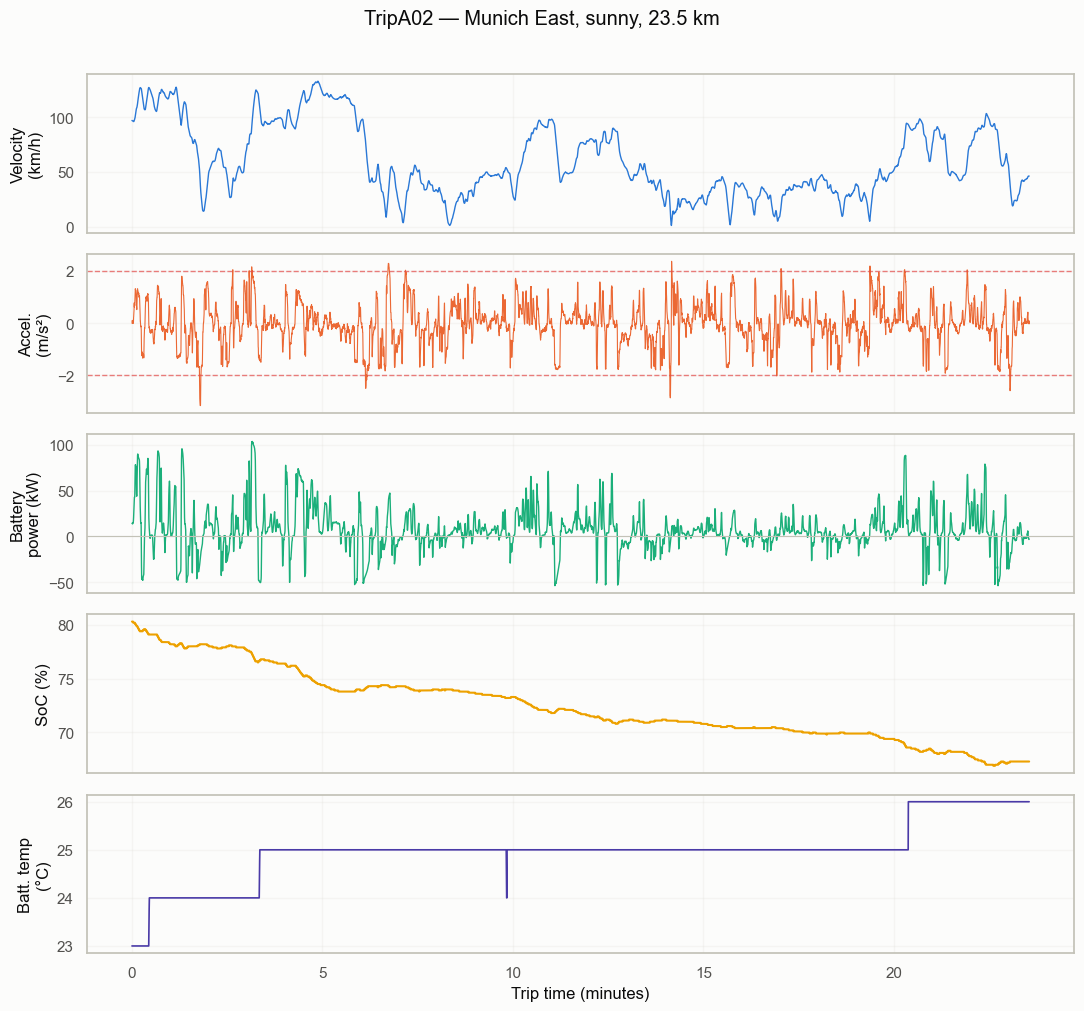

In [6]:
example_trip_id = "TripA02"
ex = trips[example_trip_id]
t_min = ex["time_s"] / 60.0

fig, axes = plt.subplots(5, 1, figsize=(11, 10), sharex=True)

axes[0].plot(t_min, ex["velocity_kmh"], color=PALETTE[0], lw=1)
axes[0].set_ylabel("Velocity\n(km/h)")

axes[1].plot(t_min, ex["accel_smooth"], color=PALETTE[1], lw=0.8)
axes[1].axhline(HARD_ACCEL_THRESH, color=PALETTE[7], ls="--", lw=1, alpha=0.7)
axes[1].axhline(HARD_BRAKE_THRESH, color=PALETTE[7], ls="--", lw=1, alpha=0.7)
axes[1].set_ylabel("Accel.\n(m/s²)")

axes[2].plot(t_min, -ex["batt_voltage_v"] * ex["batt_current_a"] / 1000.0, color=PALETTE[2], lw=1)
axes[2].axhline(0, color="#c3c2b7", lw=0.8)
axes[2].set_ylabel("Battery\npower (kW)")

axes[3].plot(t_min, ex["soc_pct"], color=PALETTE[3], lw=1.5)
axes[3].set_ylabel("SoC (%)")

axes[4].plot(t_min, ex["batt_temp_c"], color=PALETTE[6], lw=1.2)
axes[4].set_ylabel("Batt. temp\n(°C)")
axes[4].set_xlabel("Trip time (minutes)")

fig.suptitle(f"{example_trip_id} — {meta_by_trip[example_trip_id]['route']}, "
             f"{meta_by_trip[example_trip_id]['weather']}, "
             f"{meta_by_trip[example_trip_id]['distance_km']:.1f} km", y=1.01)
for ax in axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "02_example_trip_timeseries.png"), dpi=130, bbox_inches="tight")
plt.show()

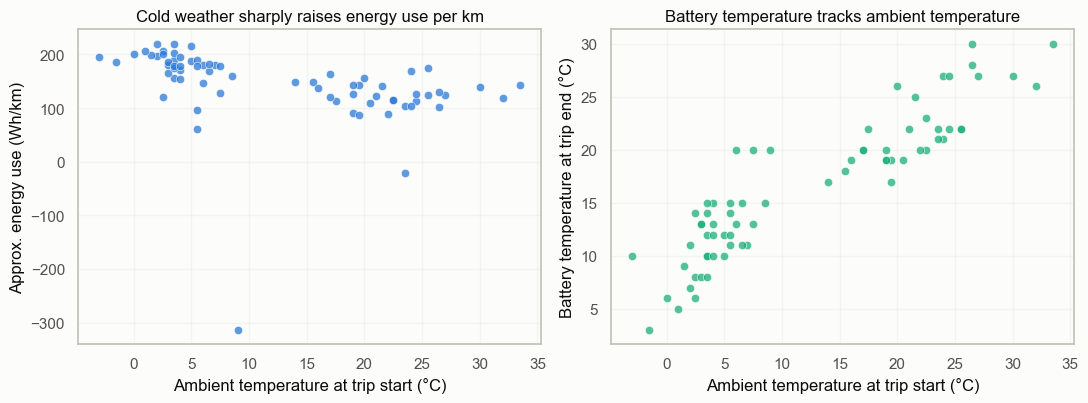

Correlation of ambient temp with Wh/km: -0.36, with end battery temp: 0.91


In [7]:
overview["soc_used_pct_pts"] = (overview["soc_start_frac"] - overview["soc_end_frac"]) * 100
overview["wh_per_km_trip"] = (overview["soc_used_pct_pts"] / 100 * NOMINAL_CAPACITY_AH
                               * 360.0) / overview["distance_km"]  # approx pack nominal V=360

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].scatter(overview["ambient_temp_start_c"], overview["wh_per_km_trip"],
                color=PALETTE[0], alpha=0.75, edgecolor="white", linewidth=0.5)
axes[0].set_xlabel("Ambient temperature at trip start (°C)")
axes[0].set_ylabel("Approx. energy use (Wh/km)")
axes[0].set_title("Cold weather sharply raises energy use per km")

axes[1].scatter(overview["ambient_temp_start_c"], overview["batt_temp_end_c"],
                color=PALETTE[2], alpha=0.75, edgecolor="white", linewidth=0.5)
axes[1].set_xlabel("Ambient temperature at trip start (°C)")
axes[1].set_ylabel("Battery temperature at trip end (°C)")
axes[1].set_title("Battery temperature tracks ambient temperature")

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "03_ambient_temp_effects.png"), dpi=130)
plt.show()

corr = overview[["ambient_temp_start_c", "wh_per_km_trip", "batt_temp_end_c"]].corr().iloc[0]
print(f"Correlation of ambient temp with Wh/km: {corr['wh_per_km_trip']:.2f}, "
      f"with end battery temp: {corr['batt_temp_end_c']:.2f}")

## Section 3 — Sliding Windows & Feature Engineering

Each trip is cut into overlapping 60 s windows (30 s step). For every window we compute the driving-behaviour and battery metrics the module requires: average speed, acceleration statistics, hard-acceleration/hard-braking event counts, idle-time percentage, regenerative-braking percentage, battery power, energy consumption, and battery-temperature/C-rate/SoC statistics used later to build the stress-index label.

Windows that are essentially stationary (< 100 m covered — e.g. the one fast-charging stop in `TripB09`, noted in `Overview.xlsx`) are dropped: they aren't "driving" and would blow up the Wh/km denominator.

In [8]:
def count_events(mask):
    """Count contiguous runs of True (e.g. one hard-braking *event*, not one sample)."""
    m = mask.astype(int).values
    d = np.diff(m, prepend=0, append=0)
    return int((d == 1).sum())


def window_features(w, trip_id, window_idx, meta):
    t = w["time_s"].values
    dt = np.diff(t, prepend=t[0])
    v_kmh = w["velocity_kmh"].values
    v_ms = v_kmh / 3.6
    a = w["accel_smooth"].values
    I = w["batt_current_a"].values
    V = w["batt_voltage_v"].values
    soc = w["soc_pct"].values
    batt_temp = w["batt_temp_c"].values
    ambient = w["ambient_temp_c"].values

    power_kw = -(V * I) / 1000.0  # positive = discharging (drawing power to drive)
    distance_km = np.sum(v_ms * dt) / 1000.0
    energy_wh = np.sum(power_kw * dt) / 3600.0 * 1000.0

    hard_accel_mask = pd.Series(a > HARD_ACCEL_THRESH)
    hard_brake_mask = pd.Series(a < HARD_BRAKE_THRESH)
    braking_mask = a < BRAKING_ACCEL_THRESH
    regen_active = w["regen_signal"].astype(float).values > 0

    regen_pct = 100.0 * regen_active[braking_mask].sum() / max(braking_mask.sum(), 1)
    idle_pct = 100.0 * np.sum(v_kmh < IDLE_SPEED_KMH) / len(v_kmh)
    c_rate = np.abs(I) / NOMINAL_CAPACITY_AH
    jerk = np.diff(a) / dt[1:]

    return {
        "trip_id": trip_id, "window_idx": window_idx, "window_start_s": t[0],
        # -- driving-behaviour features (model input) --
        "avg_speed_kmh": np.mean(v_kmh), "speed_std_kmh": np.std(v_kmh), "max_speed_kmh": np.max(v_kmh),
        "accel_mean": np.mean(a), "accel_std": np.std(a), "accel_max": np.max(a), "accel_min": np.min(a),
        "jerk_std": np.std(jerk),
        "hard_accel_count": count_events(hard_accel_mask), "hard_brake_count": count_events(hard_brake_mask),
        "idle_time_pct": idle_pct, "regen_braking_pct": regen_pct,
        "ambient_temp_mean_c": np.mean(ambient),
        # -- battery/energy features (reported + used to build the stress-index label) --
        "battery_power_kw_mean": np.mean(power_kw), "battery_power_kw_max": np.max(power_kw),
        "energy_consumption_wh_per_km": energy_wh / distance_km if distance_km > 0.01 else np.nan,
        "distance_km": distance_km,
        "battery_temp_mean_c": np.mean(batt_temp), "battery_temp_max_c": np.max(batt_temp),
        "battery_temp_rise_c": batt_temp[-1] - batt_temp[0],
        "c_rate_mean": np.mean(c_rate), "c_rate_max": np.max(c_rate),
        "soc_mean": np.mean(soc), "soc_delta": soc[0] - soc[-1],
        "soc_min": np.min(soc), "soc_max": np.max(soc),
        # -- context --
        "route": meta["route"], "weather": meta["weather"],
    }


def build_window_dataset():
    win_n, step_n = WINDOW_S * FS_HZ, STEP_S * FS_HZ
    rows = []
    for trip_id, df in trips.items():
        meta = meta_by_trip[trip_id]
        n = len(df)
        widx = 0
        for start in range(0, max(n - win_n, 0) + 1, step_n):
            w = df.iloc[start:start + win_n]
            if len(w) < win_n:
                continue
            rows.append(window_features(w, trip_id, widx, meta))
            widx += 1
    fd = pd.DataFrame(rows)
    before = len(fd)
    fd = fd[fd["distance_km"] >= MIN_WINDOW_DISTANCE_KM].reset_index(drop=True)
    print(f"Built {before} windows -> dropped {before - len(fd)} near-stationary/charging windows "
          f"-> {len(fd)} driving windows kept, across {fd['trip_id'].nunique()} trips")
    return fd


window_df = build_window_dataset()
window_df.describe().T

Built 3544 windows -> dropped 351 near-stationary/charging windows -> 3193 driving windows kept, across 70 trips


,count,mean,std,min,25%,50%,75%,max
window_idx,3193.0,30.402756,23.948985,0.000000e+00,12.000000,25.000000,42.000000,125.000000
window_start_s,3193.0,912.082681,718.469562,0.000000e+00,360.000000,750.000000,1260.000000,3750.000000
avg_speed_kmh,3193.0,50.483916,30.807078,6.026183e+00,26.028333,42.469400,70.257867,143.960617
speed_std_kmh,3193.0,11.728898,7.372176,7.105427e-15,5.992980,10.469937,16.112815,48.513136
max_speed_kmh,3193.0,68.310327,29.406513,1.222000e+01,46.360000,60.380000,86.720000,152.260000
accel_mean,3193.0,0.007624,0.175213,-8.411167e-01,-0.092383,0.003517,0.098033,2.150033
accel_std,3193.0,0.568595,0.261735,0.000000e+00,0.350747,0.557802,0.750057,1.540398
accel_max,3193.0,1.517130,0.789817,-9.000000e-02,0.870000,1.480000,2.040000,4.240000
accel_min,3193.0,-1.400763,0.727129,-7.840000e+00,-1.760000,-1.470000,-0.890000,1.610000
jerk_std,3193.0,0.667757,0.257617,0.000000e+00,0.476335,0.639696,0.820338,2.553848


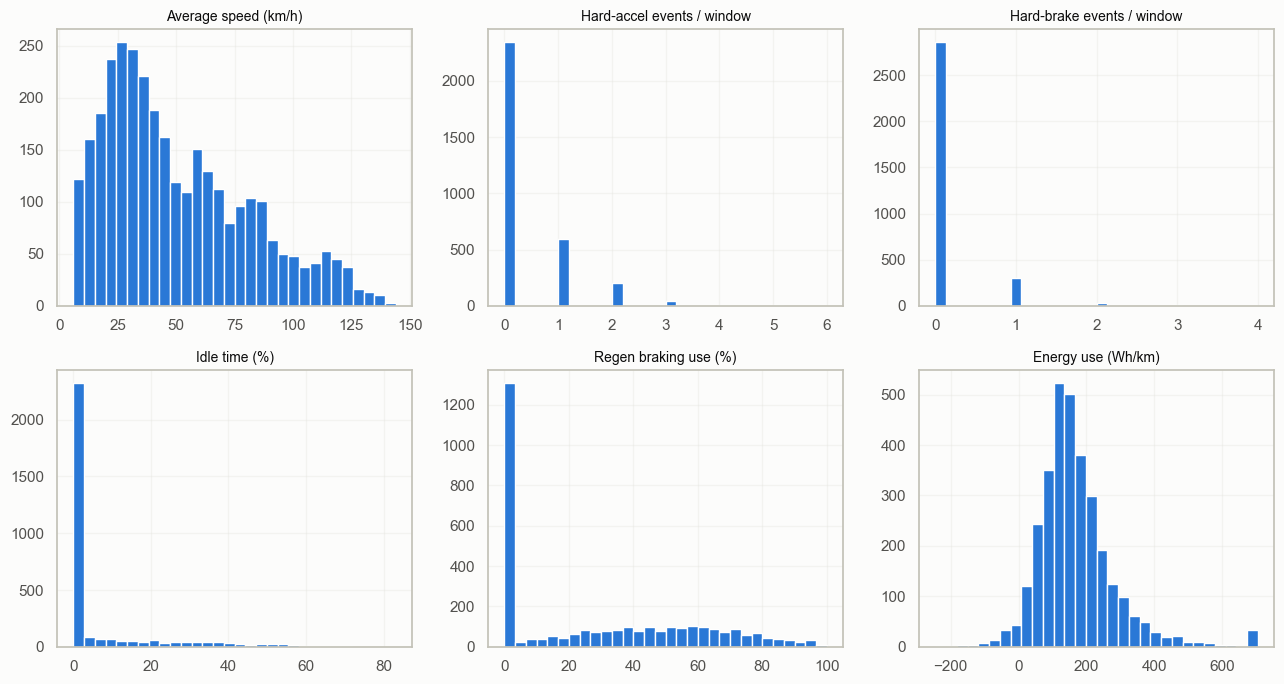

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
plot_specs = [
    ("avg_speed_kmh", "Average speed (km/h)"), ("hard_accel_count", "Hard-accel events / window"),
    ("hard_brake_count", "Hard-brake events / window"), ("idle_time_pct", "Idle time (%)"),
    ("regen_braking_pct", "Regen braking use (%)"), ("energy_consumption_wh_per_km", "Energy use (Wh/km)"),
]
for ax, (col, label) in zip(axes.flat, plot_specs):
    data = window_df[col].dropna()
    if col == "energy_consumption_wh_per_km":
        data = data.clip(upper=data.quantile(0.99))
    ax.hist(data, bins=30, color=PALETTE[0])
    ax.set_title(label, fontsize=10)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "04_window_feature_distributions.png"), dpi=130)
plt.show()

### Battery Stress Index (the modeling target) & Driver Aggressiveness Score

**Battery Stress Index** — a 0–100 composite proxy for how much aging stress a window of driving places on the battery, built from four factors with established roles in Li-ion aging literature (each min-max normalized across all windows, then weighted):

| Factor | Window feature used | Weight | Why it matters |
|---|---|---|---|
| Thermal stress | `battery_temp_max_c` | 35% | Degradation kinetics are Arrhenius-driven — higher operating temperature accelerates side reactions. |
| C-rate stress | `c_rate_max` | 30% | Higher charge/discharge current relative to pack capacity increases mechanical/thermal stress on cells. |
| Depth-of-discharge | `soc_delta` (clipped ≥ 0) | 20% | Larger SoC swings per unit time mean more cycling stress. |
| SoC-extreme exposure | time near `soc_mean` < 20% or > 80% | 15% | Cycling near full charge or deep discharge is chemically more reactive than mid-range SoC. |

These weights are a documented, transparent assumption (not fit to data) — the point is to have an interpretable, physically-motivated label to model, not to claim a precisely calibrated aging formula.

**Driver Aggressiveness Score** — a separate 0–100 composite (equal-weighted, min-max normalized) of `hard_accel_count`, `hard_brake_count`, `accel_std`, `jerk_std`, `speed_std_kmh`. This is a **model input feature**, not the target — it summarizes overall driving intensity for use both in modeling and in the recommendations later.

**Important modeling-design note:** the battery/thermal/current/SoC columns above (`battery_temp_*`, `c_rate_*`, `soc_*`, `battery_power_*`, `energy_consumption_wh_per_km`) are used only to *build* the stress-index label. They are excluded from the model's input features (Section 4) — including them would let the model trivially "predict" the label from its own ingredients. The model only ever sees driving-behaviour and context features, so SHAP's explanations genuinely describe how driving behaviour drives battery stress.

In [10]:
def minmax(s):
    lo, hi = s.min(), s.max()
    if hi - lo < 1e-9:
        return pd.Series(0.0, index=s.index)
    return (s - lo) / (hi - lo)


def add_battery_stress_index(fd):
    thermal_norm = minmax(fd["battery_temp_max_c"])
    crate_norm = minmax(fd["c_rate_max"])
    dod_norm = minmax(fd["soc_delta"].clip(lower=0))
    soc_extreme_raw = np.maximum(0, 20 - fd["soc_mean"]) + np.maximum(0, fd["soc_mean"] - 80)
    soc_extreme_norm = minmax(soc_extreme_raw)
    fd["battery_stress_index"] = 100 * (
        0.35 * thermal_norm + 0.30 * crate_norm + 0.20 * dod_norm + 0.15 * soc_extreme_norm
    )
    return fd


def add_aggressiveness_score(fd):
    components = {
        "hard_accel_count": minmax(fd["hard_accel_count"]),
        "hard_brake_count": minmax(fd["hard_brake_count"]),
        "accel_std": minmax(fd["accel_std"]),
        "jerk_std": minmax(fd["jerk_std"]),
        "speed_std_kmh": minmax(fd["speed_std_kmh"]),
    }
    fd["driver_aggressiveness_score"] = 100 * sum(components.values()) / len(components)
    return fd


LABEL_COMPONENT_COLS = [
    "battery_temp_mean_c", "battery_temp_max_c", "battery_temp_rise_c",
    "c_rate_mean", "c_rate_max", "soc_delta", "soc_mean", "soc_min", "soc_max",
    "battery_power_kw_mean", "battery_power_kw_max", "energy_consumption_wh_per_km",
]
MODEL_FEATURE_COLS = [
    "avg_speed_kmh", "speed_std_kmh", "max_speed_kmh",
    "accel_mean", "accel_std", "accel_max", "accel_min", "jerk_std",
    "hard_accel_count", "hard_brake_count", "idle_time_pct", "regen_braking_pct",
    "driver_aggressiveness_score", "ambient_temp_mean_c",
]

window_df = add_battery_stress_index(window_df)
window_df = add_aggressiveness_score(window_df)
window_df[["battery_stress_index", "driver_aggressiveness_score"]].describe()

,battery_stress_index,driver_aggressiveness_score
count,3193.000000,3193.000000
mean,29.632990,19.286127
std,10.719036,9.818585
min,3.850068,0.000000
25%,21.849886,11.429042
50%,28.641619,17.825728
75%,36.066877,25.326726
max,71.906971,61.000683


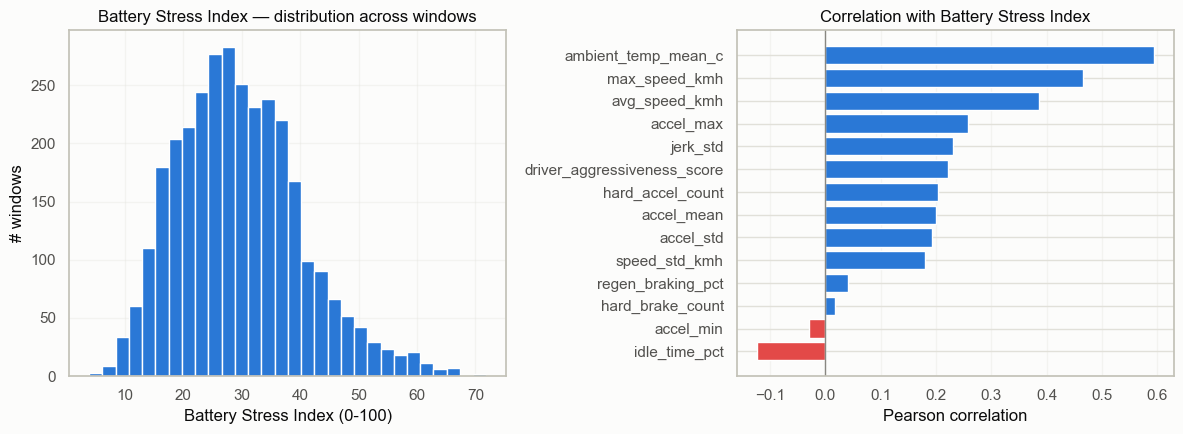

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(window_df["battery_stress_index"], bins=30, color=PALETTE[0])
axes[0].set_title("Battery Stress Index — distribution across windows")
axes[0].set_xlabel("Battery Stress Index (0-100)")
axes[0].set_ylabel("# windows")
axes[0].grid(alpha=0.3)

corr = window_df[MODEL_FEATURE_COLS + ["battery_stress_index"]].corr()["battery_stress_index"].drop("battery_stress_index")
corr = corr.sort_values()
colors = [PALETTE[0] if v >= 0 else PALETTE[7] for v in corr.values]
axes[1].barh(corr.index, corr.values, color=colors)
axes[1].axvline(0, color="#898781", lw=1)
axes[1].set_title("Correlation with Battery Stress Index")
axes[1].set_xlabel("Pearson correlation")
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "05_stress_index_correlations.png"), dpi=130)
plt.show()

## Section 4 — Modeling: Predicting Battery Stress from Driving Behaviour

The model's job: given only driving-behaviour features for a 60 s window (plus ambient temperature and route/weather context), predict the Battery Stress Index. We compare a linear baseline against Random Forest and XGBoost, and evaluate with **`GroupKFold` split by `trip_id`** — windows from the same trip never appear in both train and test, so the reported performance reflects generalization to *unseen trips*, not memorized within-trip patterns.

Route and weather categories that appear in fewer than 3 trips are folded into "Other" first — otherwise a rare route can act as a near trip-identifier and inflate apparent performance without teaching us anything about driving behaviour.

In [12]:
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.linear_model import LinearRegression, ElasticNetCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import xgboost as xgb

def prepare_model_dataset(fd):
    cat_cols = ["route", "weather"]
    fd = fd.copy()
    for c in cat_cols:
        trip_level = fd.drop_duplicates("trip_id")[c]
        rare = trip_level.value_counts()[lambda s: s < 3].index
        fd[c] = fd[c].where(~fd[c].isin(rare), "Other")
    X = pd.get_dummies(fd[MODEL_FEATURE_COLS + cat_cols], columns=cat_cols, drop_first=True)
    y = fd["battery_stress_index"]
    groups = fd["trip_id"]
    return fd, X, y, groups


def evaluate_grouped(model, X, y, groups, name, n_splits=5):
    gkf = GroupKFold(n_splits=n_splits)
    r2s, rmses, maes = [], [], []
    for train_idx, test_idx in gkf.split(X, y, groups):
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        pred = model.predict(X.iloc[test_idx])
        r2s.append(r2_score(y.iloc[test_idx], pred))
        rmses.append(np.sqrt(mean_squared_error(y.iloc[test_idx], pred)))
        maes.append(mean_absolute_error(y.iloc[test_idx], pred))
    return {"model": name, "R2_mean": np.mean(r2s), "R2_std": np.std(r2s),
            "RMSE_mean": np.mean(rmses), "MAE_mean": np.mean(maes)}


window_df, X, y, groups = prepare_model_dataset(window_df)
print(f"Feature matrix: {X.shape[0]} windows x {X.shape[1]} features (one-hot incl.)")

results = []
results.append(evaluate_grouped(LinearRegression(), X, y, groups, "Linear Regression"))
results.append(evaluate_grouped(
    RandomForestRegressor(n_estimators=300, max_depth=8, min_samples_leaf=5,
                           random_state=RANDOM_STATE, n_jobs=-1),
    X, y, groups, "Random Forest"))
results.append(evaluate_grouped(
    xgb.XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                      colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1),
    X, y, groups, "XGBoost"))

# ElasticNet needs standardized inputs (its L1/L2 penalty is scale-sensitive, unlike OLS
# or tree splits) -- StandardScaler is folded into the pipeline so each grouped-CV fold
# fits its own scaler on that fold's training data only, no leakage. Regularization
# strength (alpha) and the L1/L2 mix (l1_ratio) are picked by ElasticNetCV's own internal
# 5-fold CV inside every outer grouped-CV fold, rather than hand-picked -- so this is a
# fair, non-cherry-picked ElasticNet result, at the cost of nested-CV runtime.
elasticnet_model = make_pipeline(
    StandardScaler(),
    ElasticNetCV(l1_ratio=[.1, .3, .5, .7, .9, .95, 1.0], n_alphas=50,
                 cv=5, random_state=RANDOM_STATE, max_iter=10000)
)
results.append(evaluate_grouped(elasticnet_model, X, y, groups, "ElasticNet"))

results_df = pd.DataFrame(results).set_index("model").round(3)
results_df

Feature matrix: 3193 windows x 24 features (one-hot incl.)


,R2_mean,R2_std,RMSE_mean,MAE_mean
model,,,,
Linear Regression,0.553,0.183,6.625,5.189
Random Forest,0.704,0.084,5.482,4.363
XGBoost,0.708,0.094,5.419,4.250
ElasticNet,0.585,0.135,6.478,5.098


Held-out trips: 14 trips, 741 windows
Test R2=0.737  RMSE=5.69  MAE=4.58


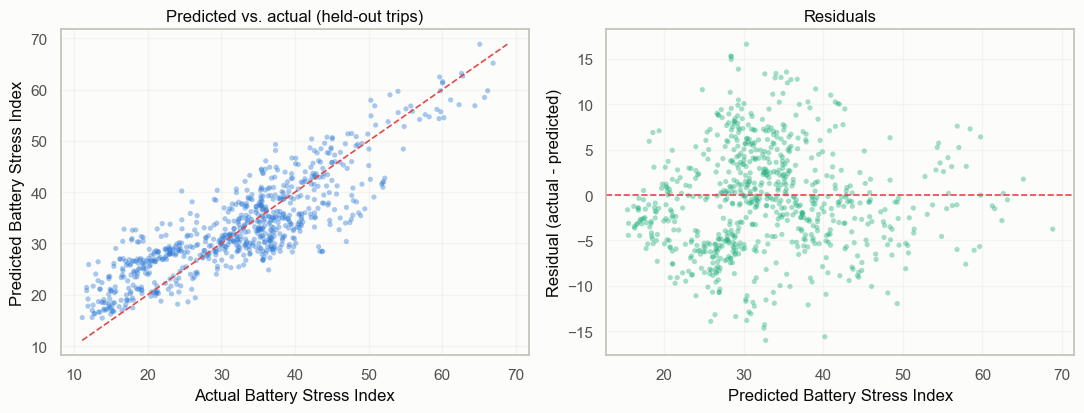

In [13]:
# XGBoost wins on R2/RMSE/MAE with grouped CV -> it's our final model.
# Fit once on a held-out 80/20 trip split (kept fixed for the SHAP + recommendation sections below).
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))

final_model = xgb.XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                                 colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1)
final_model.fit(X.iloc[train_idx], y.iloc[train_idx])
y_pred = final_model.predict(X.iloc[test_idx])
y_test = y.iloc[test_idx]

print(f"Held-out trips: {groups.iloc[test_idx].nunique()} trips, {len(test_idx)} windows")
print(f"Test R2={r2_score(y_test, y_pred):.3f}  RMSE={np.sqrt(mean_squared_error(y_test, y_pred)):.2f}"
      f"  MAE={mean_absolute_error(y_test, y_pred):.2f}")

final_model.save_model(os.path.join(OUT_MODEL_DIR, "xgb_battery_stress_model.json"))
window_df.to_csv(os.path.join(OUT_DATA_DIR, "window_features.csv"), index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
axes[0].scatter(y_test, y_pred, alpha=0.4, s=14, color=PALETTE[0], edgecolor="none")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, color=PALETTE[7], lw=1.2, ls="--")
axes[0].set_xlabel("Actual Battery Stress Index")
axes[0].set_ylabel("Predicted Battery Stress Index")
axes[0].set_title("Predicted vs. actual (held-out trips)")

resid = y_test - y_pred
axes[1].scatter(y_pred, resid, alpha=0.4, s=14, color=PALETTE[2], edgecolor="none")
axes[1].axhline(0, color=PALETTE[7], lw=1.2, ls="--")
axes[1].set_xlabel("Predicted Battery Stress Index")
axes[1].set_ylabel("Residual (actual - predicted)")
axes[1].set_title("Residuals")

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "06_model_fit.png"), dpi=130)
plt.show()

## Section 5 — Explainability with SHAP

Which specific driving characteristics push the model's predicted Battery Stress Index up or down? `TreeExplainer` gives exact Shapley values for the XGBoost model — a beeswarm summary (global ranking + direction of effect), a mean-|SHAP| bar chart, and dependence plots for the top behavioural drivers.

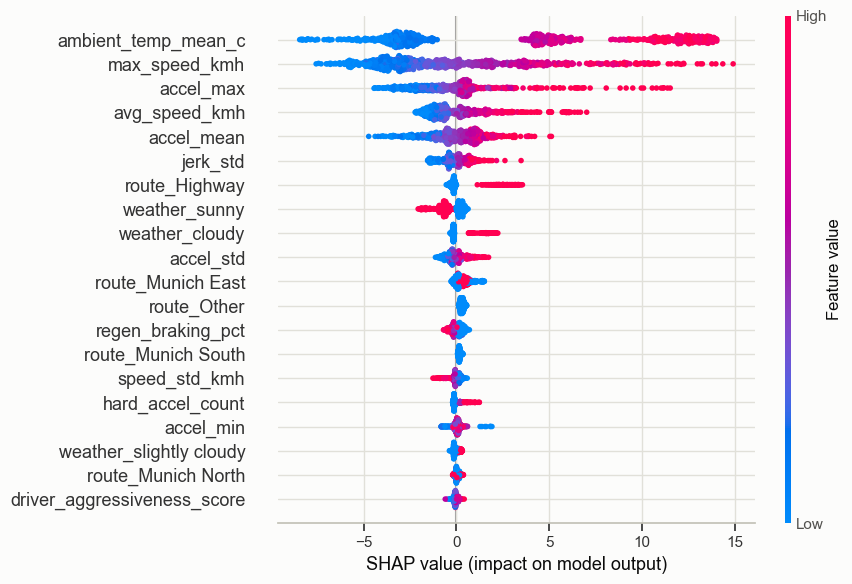

In [14]:
import shap

explainer = shap.TreeExplainer(final_model)
shap_values_test = explainer.shap_values(X.iloc[test_idx])
shap_df_test = pd.DataFrame(shap_values_test, columns=X.columns, index=X.iloc[test_idx].index)

shap.summary_plot(shap_values_test, X.iloc[test_idx], show=False, plot_size=(9, 6))
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "07_shap_beeswarm.png"), dpi=130, bbox_inches="tight")
plt.show()

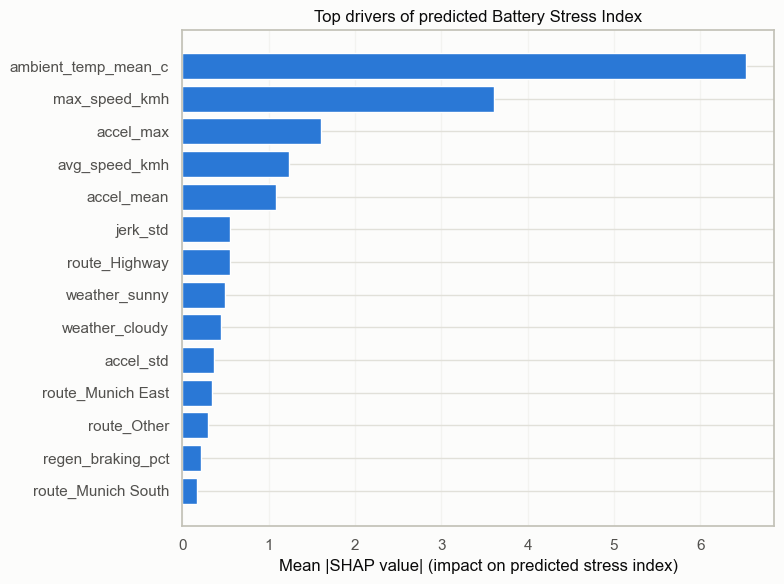

Top behavioural (non-context) drivers:
ambient_temp_mean_c    6.526162
max_speed_kmh          3.612440
accel_max              1.600991
avg_speed_kmh          1.240144
accel_mean             1.084200
jerk_std               0.557053
dtype: float32


In [15]:
mean_abs_shap = shap_df_test.abs().mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
top = mean_abs_shap.head(14).iloc[::-1]
ax.barh(top.index, top.values, color=PALETTE[0])
ax.set_xlabel("Mean |SHAP value| (impact on predicted stress index)")
ax.set_title("Top drivers of predicted Battery Stress Index")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "08_shap_importance_bar.png"), dpi=130)
plt.show()

behavioural_only = [c for c in mean_abs_shap.index if c in MODEL_FEATURE_COLS]
print("Top behavioural (non-context) drivers:")
print(mean_abs_shap.reindex(behavioural_only).head(6))

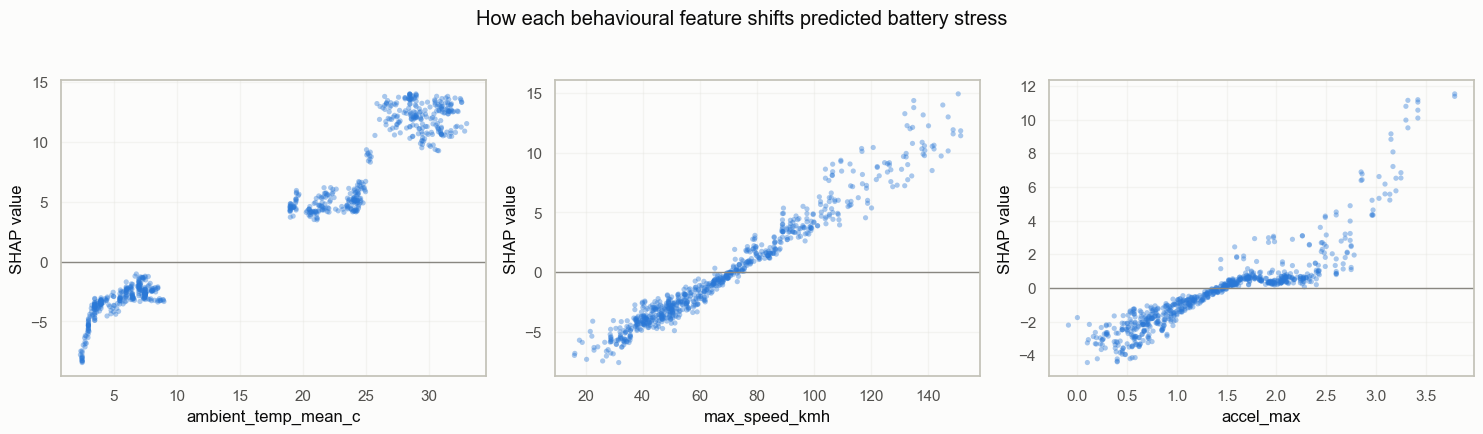

In [16]:
top_behavioural = mean_abs_shap.reindex(behavioural_only).head(3).index.tolist()
fig, axes = plt.subplots(1, len(top_behavioural), figsize=(5 * len(top_behavioural), 4.2))
for ax, feat in zip(axes, top_behavioural):
    ax.scatter(X.iloc[test_idx][feat], shap_df_test[feat], alpha=0.4, s=14,
               color=PALETTE[0], edgecolor="none")
    ax.axhline(0, color="#898781", lw=1)
    ax.set_xlabel(feat)
    ax.set_ylabel("SHAP value")
    ax.grid(alpha=0.3)
fig.suptitle("How each behavioural feature shifts predicted battery stress", y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(OUT_FIG_DIR, "09_shap_dependence.png"), dpi=130, bbox_inches="tight")
plt.show()

## Section 6 — Personalized Driving Recommendations

For any trip, we take the mean SHAP contribution of each *controllable* behavioural feature across that trip's windows, keep the ones pushing predicted stress **up**, and turn the top few into plain-language, personalized advice — with the trip's actual value and its percentile against all 3,193 windows in the dataset for context. Context features the driver can't control (ambient temperature, weather) are excluded from recommendations, though they remain in the model and in the SHAP plots above since they are real, legitimate contributors to battery stress.

We compute SHAP values for every window in the dataset (not just the held-out test set) so that any of the 70 trips can get a recommendation, not only the ones in the test split.

In [17]:
CONTROLLABLE_FEATURES = [
    "hard_accel_count", "hard_brake_count", "accel_max", "accel_mean", "accel_std",
    "jerk_std", "avg_speed_kmh", "max_speed_kmh", "speed_std_kmh", "regen_braking_pct",
    "driver_aggressiveness_score",
]

RECOMMENDATION_TEMPLATES = {
    "hard_accel_count": "Hard-acceleration events average {value:.1f} per window on this trip ({pct} percentile across all trips). Easing off the accelerator lowers peak current draw (C-rate), one of the biggest drivers of battery stress.",
    "hard_brake_count": "Hard-braking events average {value:.1f} per window ({pct} percentile). Anticipating stops earlier allows more gradual deceleration and more regenerative (rather than friction) braking.",
    "accel_max": "Peak acceleration reaches {value:.2f} m/s² ({pct} percentile). Smoother throttle inputs reduce instantaneous power spikes that stress the battery.",
    "accel_mean": "Average acceleration intensity is at the {pct} percentile among all trips — a generally brisker driving style increases sustained battery load.",
    "accel_std": "Acceleration varies a lot on this trip ({pct} percentile in variability). More consistent, steady-state driving reduces battery cycling stress.",
    "jerk_std": "Throttle/brake transitions are abrupt ({pct} percentile in jerk). Smoother pedal transitions reduce current spikes.",
    "avg_speed_kmh": "Average speed is {value:.0f} km/h ({pct} percentile). Sustained high speed keeps discharge current elevated for longer.",
    "max_speed_kmh": "Top speed reached {value:.0f} km/h ({pct} percentile). High-speed segments (e.g. highway) draw sustained high current and raise battery temperature.",
    "speed_std_kmh": "Speed fluctuates significantly ({pct} percentile). Stop-and-go driving causes repeated high-current bursts; maintaining a steadier pace helps.",
    "regen_braking_pct": "Only {value:.0f}% of braking on this trip used regenerative braking ({pct} percentile). Lifting off earlier to trigger regen more often improves efficiency and reduces reliance on friction brakes.",
    "driver_aggressiveness_score": "Overall driving-aggressiveness score is {value:.0f}/100 ({pct} percentile across all trips) — driven by the specific behaviours listed above.",
}


def ordinal(n):
    n = int(round(n))
    suffix = "th" if 10 <= n % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(n % 10, "th")
    return f"{n}{suffix}"


def generate_trip_recommendations(trip_id, fd, X, shap_df, top_k=3):
    mask = (fd["trip_id"].values == trip_id)
    if mask.sum() == 0:
        return []
    trip_shap_mean = shap_df.loc[mask].mean()
    candidates = trip_shap_mean.reindex(CONTROLLABLE_FEATURES).dropna()
    positive = candidates[candidates > 0].sort_values(ascending=False)

    recs = []
    for feat in positive.index[:top_k]:
        value = fd.loc[mask, feat].mean()
        pct = ordinal(100 * (X[feat] < value).mean())
        template = RECOMMENDATION_TEMPLATES.get(feat)
        if template:
            recs.append(template.format(value=value, pct=pct))
    if not recs:
        recs.append("This trip's driving behaviour looks smooth and battery-friendly — "
                     "no major stress-inducing patterns detected.")
    return recs


# SHAP values for every window (needed so any trip, not just held-out ones, gets a recommendation)
shap_values_all = explainer.shap_values(X)
shap_df_all = pd.DataFrame(shap_values_all, columns=X.columns, index=X.index)

In [18]:
trip_stress = window_df.groupby("trip_id")["battery_stress_index"].mean().sort_values()
sample_trips = [trip_stress.index[0], trip_stress.index[len(trip_stress)//2], trip_stress.index[-1]]
labels = ["Lowest-stress trip", "Median-stress trip", "Highest-stress trip"]

for label, tid in zip(labels, sample_trips):
    print(f"--- {label}: {tid}  (mean stress index = {trip_stress[tid]:.1f}/100, "
          f"route: {meta_by_trip[tid]['route']}, weather: {meta_by_trip[tid]['weather']}) ---")
    for rec in generate_trip_recommendations(tid, window_df, X, shap_df_all):
        print("  •", rec)
    print()

--- Lowest-stress trip: TripB38  (mean stress index = 14.2/100, route: FTMRoute reverse, weather: sunny) ---
  • Peak acceleration reaches 1.85 m/s² (68th percentile). Smoother throttle inputs reduce instantaneous power spikes that stress the battery.
  • Acceleration varies a lot on this trip (72nd percentile in variability). More consistent, steady-state driving reduces battery cycling stress.
  • Only 30% of braking on this trip used regenerative braking (54th percentile). Lifting off earlier to trigger regen more often improves efficiency and reduces reliance on friction brakes.

--- Median-stress trip: TripA28  (mean stress index = 29.3/100, route: Munich East, weather: sunny) ---
  • Peak acceleration reaches 1.67 m/s² (59th percentile). Smoother throttle inputs reduce instantaneous power spikes that stress the battery.

--- Highest-stress trip: TripA04  (mean stress index = 55.4/100, route: Munich East, weather: sunny) ---
  • Top speed reached 126 km/h (94th percentile). High-s

## Summary & Limitations

**What this module delivers:** a full pipeline from raw 10 Hz Munich EV telemetry to personalized, explainable driving guidance — robust preprocessing (schema-variable columns, coulomb-counting SoC reconstruction, noise filtering), trip- and window-level EDA, 24 engineered driving-behaviour and battery features, a transparent physics-informed Battery Stress Index label, an XGBoost model (R² ≈ 0.7 on held-out trips) that predicts it from driving behaviour alone, SHAP explanations of what drives it, and a rule-based recommendation generator driven directly by those SHAP explanations.

**Key finding:** ambient temperature and speed/route intensity are the largest contributors to predicted battery stress — but driving style (hard acceleration/braking, jerk, acceleration variability) is a consistent secondary contributor and, unlike ambient conditions, is the part a driver can actually act on. That's the basis for the recommendations above.

**Limitations to keep in mind:**
- The Battery Stress Index is a **constructed proxy**, not a measured aging outcome — this dataset has no capacity-fade/SOH ground truth to validate against (single vehicle, 8-month span). The weights (35/30/20/15%) are a documented assumption, not fit or calibrated to real aging data.
- All 70 trips come from **one vehicle** — "personalization" here means per-trip/per-session, not per-distinct-driver, since the dataset doesn't identify multiple drivers.
- The 60 Ah nominal pack capacity is an assumption (validated against one trip's measured SoC delta, §1) — a different real capacity would rescale C-rate and the coulomb-counted SoC reconstruction proportionally.
- With genuine long-term capacity-fade data (e.g. periodic SOH measurements across a fleet), the same feature-engineering pipeline could support a real degradation-regression model instead of a proxy-index one — that would be the natural next step beyond this dataset.